In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
houses = pd.read_csv('houses.csv')
print(houses.shape)
houses.head()

(200, 5)


,size_marla,bedrooms,age_years,distance_km,price_lakh
0,11,5,4,7.7,131.3
1,12,5,17,14.2,113.5
2,16,5,4,14.4,170.9
3,20,8,12,13.0,185.3
4,3,3,21,11.2,31.2


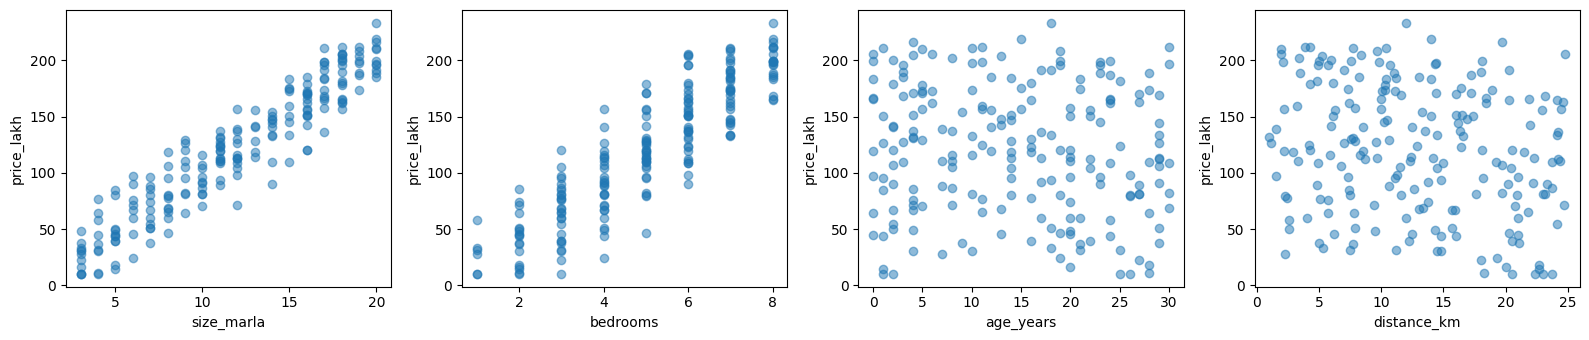

In [3]:
features = ["size_marla", "bedrooms", "age_years", "distance_km"]

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, col in zip(axes, features):
    ax.scatter(houses[col], houses["price_lakh"], alpha=0.5)
    ax.set_xlabel(col)
    ax.set_ylabel("price_lakh")
plt.tight_layout()
plt.show()

In [4]:
houses.corr()['price_lakh'].round(2)

size_marla     0.95
bedrooms       0.89
age_years     -0.11
distance_km   -0.21
price_lakh     1.00
Name: price_lakh, dtype: float64

In [5]:
features = ["size_marla", "bedrooms", "age_years", "distance_km"]
x = houses[features]
y= houses['price_lakh']

x.shape,y.shape

((200, 4), (200,))

In [7]:
from sklearn.model_selection import train_test_split

In [11]:
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2, random_state=42)
len(X_train),len(x_test)

(160, 40)

In [12]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error

In [13]:
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'KNN' :KNeighborsRegressor(n_neighbors=5)
}
for name , m in models.items():
    m.fit(x_train,y_train)
    err = mean_absolute_error(y_test,m.predict(x_test))
    print(name,"avg err:", round(err,1), "lakh")

Linear Regression avg err: 11.8 lakh
Decision Tree avg err: 18.0 lakh
KNN avg err: 13.7 lakh


ml work flow 

look at the data set->prepare x,y -> choose a model -> train -> predict-> residuals measure the error

In [28]:
line_model = LinearRegression()
line_model.fit(x_train[["size_marla"]], y_train)

b1 = line_model.coef_[0]
b0 = line_model.intercept_
print("slope (β1):", round(b1, 2))
print("intercept (β0):", round(b0, 2))
print("Rule: price =", round(b0, 1), "+", round(b1, 2), "× size")

slope (β1): 10.45
intercept (β0): -3.92
Rule: price = -3.9 + 10.45 × size


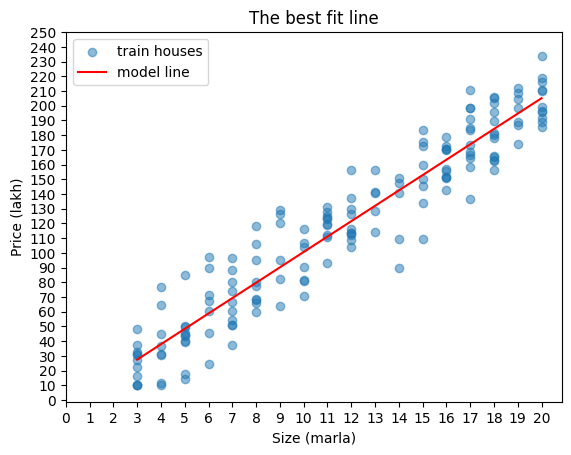

In [26]:
sizes = pd.DataFrame({"size_marla": range(3, 21)})

plt.scatter(x_train["size_marla"], y_train, alpha=0.5, label="train houses")
plt.plot(sizes["size_marla"], line_model.predict(sizes), color="red", label="model line")
plt.yticks(range(0, 251, 10))
plt.xticks(range(0,21,1))
plt.xlabel("Size (marla)")
plt.ylabel("Price (lakh)")
plt.title("The best fit line")
plt.legend()
plt.show()

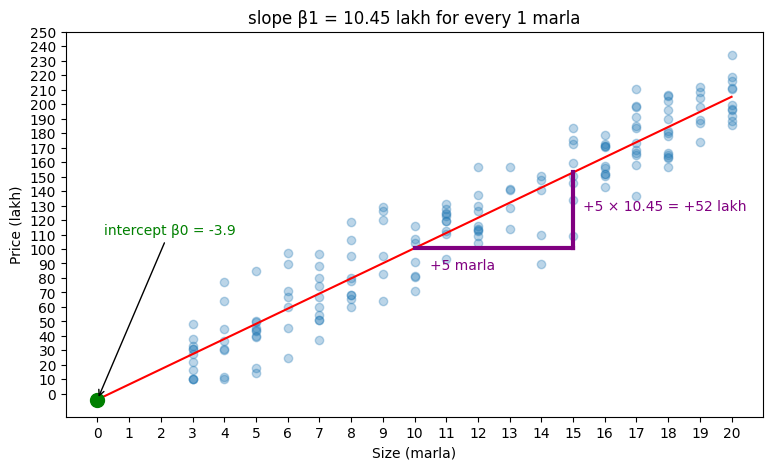

In [44]:
xs = pd.DataFrame({"size_marla": range(0, 21)})
plt.figure(figsize=(9, 5))
plt.scatter(X_train["size_marla"], y_train, alpha=0.3)
plt.plot(xs["size_marla"], line_model.predict(xs), color="red")

# intercept: the line at size = 0
plt.scatter([0], [b0], color="green", s=100, zorder=3)
plt.annotate("intercept β0 = " + str(round(b0, 1)), (0, b0), xytext=(0.2, 110),
             arrowprops={"arrowstyle": "->"}, color="green")

# slope: 5 marla right → 5 × β1 lakh up
x1 = 10
y1 = b0 + b1 * x1
plt.plot([x1, x1 + 5], [y1, y1], color="purple", linewidth=3)                 # 5 marla right
plt.plot([x1 + 5, x1 + 5], [y1, y1 + 5 * b1], color="purple", linewidth=3)    # 5 × β1 up
plt.text(x1 + 0.5, y1 - 15, "+5 marla", color="purple")
plt.text(x1 + 5.3, y1 + 2.5 * b1, "+5 × " + str(round(b1, 2)) + " = +" + str(round(5 * b1)) + " lakh", color="purple")
plt.title("slope β1 = " + str(round(b1, 2)) + " lakh for every 1 marla")

plt.xlabel("Size (marla)")
plt.ylabel("Price (lakh)")
plt.yticks(range(0, 251, 10))
plt.xticks(range(0,21,1))
plt.show()

Line A → MSE: 1122.3
Line B → MSE: 693.1
Line C (fit) → MSE: 330.8


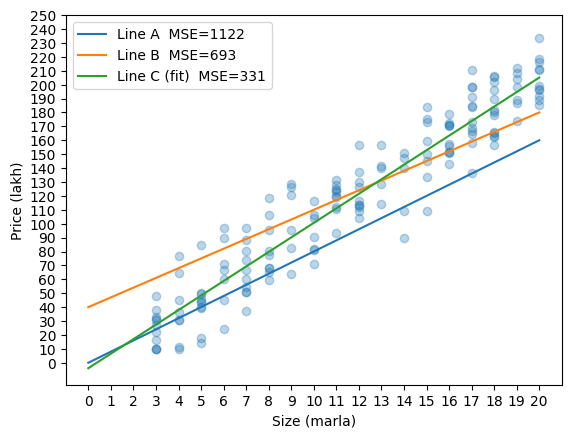

In [45]:
size = x_train["size_marla"]
price = y_train

lines = {
    "Line A": (0, 8),             # (β0, β1) we guessed
    "Line B": (40, 7),            # (β0, β1) we guessed
    "Line C (fit)": (b0, b1),     # the numbers model.fit found
}

plt.scatter(size, price, alpha=0.3)
for name, (try_b0, try_b1) in lines.items():
    guess = try_b0 + try_b1 * size                    # the line's price for every house
    mse = ((price - guess) ** 2).mean()       # average of squared residuals
    print(name, "→ MSE:", round(mse, 1))
    plt.plot(xs["size_marla"], try_b0 + try_b1 * xs["size_marla"], label=name + "  MSE=" + str(round(mse)))

plt.xlabel("Size (marla)")
plt.ylabel("Price (lakh)")
plt.legend()
plt.yticks(range(0, 251, 10))
plt.xticks(range(0,21,1))
plt.show()

### The Least Squares formula

$$\beta_1 = \frac{\sum (x - \bar{x})(y - \bar{y})}{\sum (x - \bar{x})^2} \qquad\qquad \beta_0 = \bar{y} - \beta_1 \bar{x}$$

| Symbol | Meaning | In our code |
|--------|---------|-------------|
| $x$ | size of each house | `size` |
| $y$ | price of each house | `price` |
| $\bar{x}$ ("x bar") | average size | `size_mean` |
| $\bar{y}$ ("y bar") | average price | `price_mean` |
| $\sum$ ("sigma") | add up for **all** 160 houses | `.sum()` |

**In words:**
- **slope β1** = (how much size and price move **together**) ÷ (how much size moves **alone**)
- **intercept β0** = average price − β1 × average size. So the line always goes through the **middle point** (average size, average price).

Let's use the formula with pandas, and compare with `fit`:

In [56]:
size_mean = size.mean()
price_mean = price.mean()

my_b1 = (((size - size_mean)*(price - price_mean)).sum() / ((size - size_mean)**2)).sum()
my_b0 = price_mean - my_b1 * size_mean

my_b1,my_b0

(np.float64(7730220.663627177), np.float64(-90588404.85438098))

In [57]:
print("By hand    → slope:", round(my_b1, 2), " intercept:", round(my_b0, 2))
print("model.fit  → slope:", round(line_model.coef_[0], 2), " intercept:", round(line_model.intercept_, 2))

By hand    → slope: 7730220.66  intercept: -90588404.85
model.fit  → slope: 10.45  intercept: -3.92


In [52]:
model = LinearRegression()     # 1. create
model.fit(x_train, y_train)    # 2. fit = learn from the 160 train houses

print(pd.Series(model.coef_, index=x.columns).round(2))
print("intercept:", round(model.intercept_, 1))

size_marla     7.68
bedrooms       8.26
age_years     -0.71
distance_km   -1.54
dtype: float64
intercept: 18.3


In [53]:
from sklearn.metrics import mean_squared_error, r2_score

pred = model.predict(x_test)
mse = mean_squared_error(y_test, pred)

print("MAE :", round(mean_absolute_error(y_test, pred), 1), "lakh")
print("MSE :", round(mse, 1), "lakh²")
print("RMSE:", round(mse ** 0.5, 1), "lakh")
print("R²  :", round(r2_score(y_test, pred), 2))

MAE : 11.8 lakh
MSE : 204.7 lakh²
RMSE: 14.3 lakh
R²  : 0.9


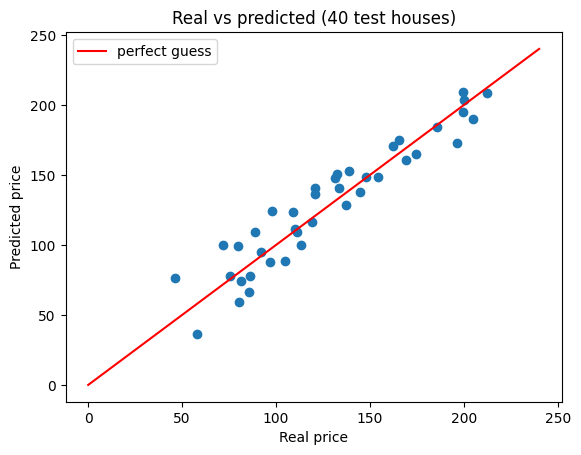

In [54]:
plt.scatter(y_test, pred)
plt.plot([0, 240], [0, 240], color="red", label="perfect guess")
plt.xlabel("Real price")
plt.ylabel("Predicted price")
plt.title("Real vs predicted (40 test houses)")
plt.legend()
plt.show()

In [55]:
new_house = pd.DataFrame({"size_marla": [10], "bedrooms": [4], "age_years": [5], "distance_km": [8]})
print("Predicted price:", model.predict(new_house)[0].round(1), "lakh")

Predicted price: 112.2 lakh
